# Module II: Autoencoders (the sketch 'ghost')
The ghost decoder is an encoder-decoder trained to reconstruct the **completed** drawing from a **partial** one. It uses transposed convolutions and a skip connection from the partial input.

In [1]:
import sys, json, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import numpy as np, matplotlib.pyplot as plt, inspect
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
res = lambda m: json.load(open(ROOT / "runs" / m / "results.json"))
from src.models.nets import GhostDecoder
print(inspect.getsource(GhostDecoder))

class GhostDecoder(nn.Module):
    """Fused feature (+ the partial raster as a skip) -> logits of the completed 64x64 drawing. Module II."""

    def __init__(self, in_dim):
        super().__init__()
        self.fc = nn.Sequential(nn.Linear(in_dim, 128 * 8 * 8), nn.ReLU(inplace=True))
        up = lambda a, b: nn.Sequential(nn.ConvTranspose2d(a, b, 4, 2, 1, bias=False), nn.BatchNorm2d(b), nn.ReLU(inplace=True))
        self.up = nn.Sequential(up(128, 64), up(64, 32), up(32, 16))
        self.out = nn.Conv2d(16 + 1, 1, 3, padding=1)

    def forward(self, feat, img):
        x = self.up(self.fc(feat).view(-1, 128, 8, 8))
        return self.out(torch.cat([x, img], dim=1))



## What the decoder predicts (held-out test sketches, 30% drawn)
Top row: what the user has drawn. Middle: the model's ghost (an expected-ink heat map). Bottom: the real finished sketch.

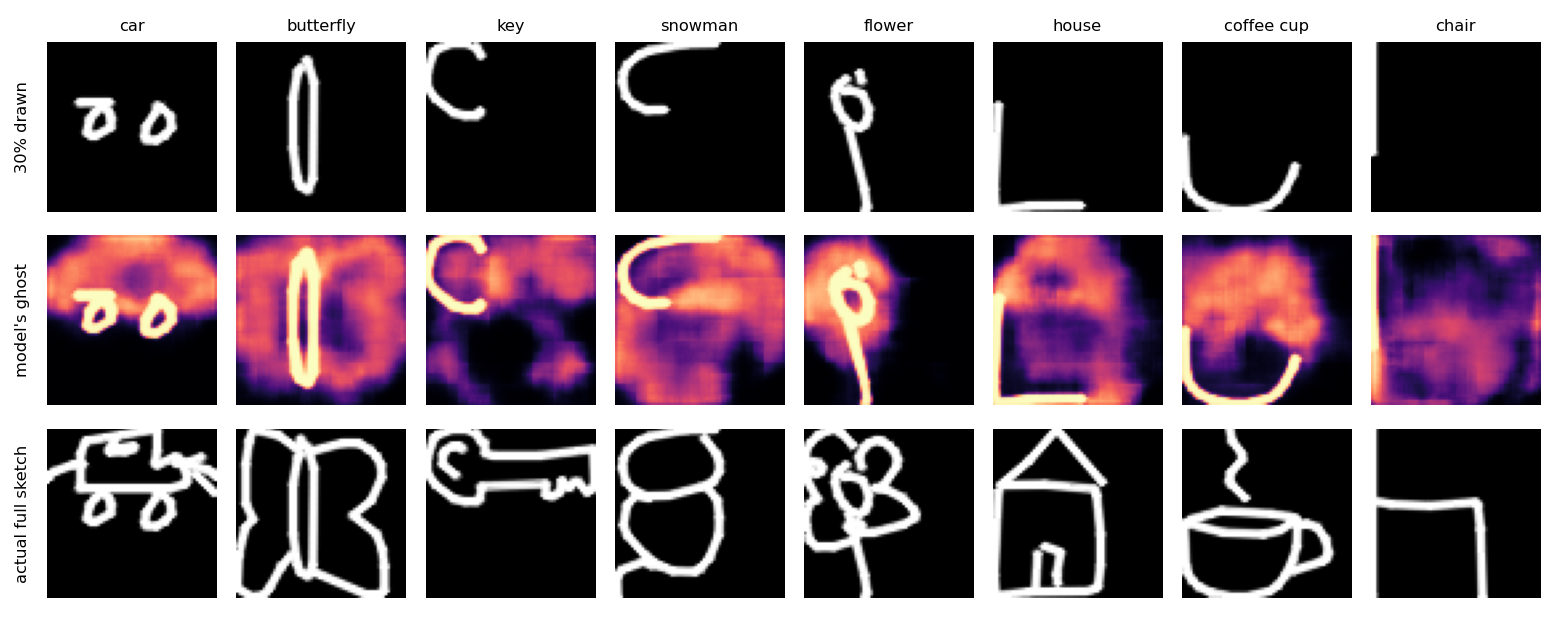

In [2]:
from IPython.display import Image
Image(str(ROOT / 'report' / 'figures' / 'ghost_gallery.png'))

The ghost is a *mean* prediction: where the object is ambiguous (e.g. a lone circle), it spreads ink over the plausible endings. That blur is the model's uncertainty, not a bug.

In [3]:
r = res('fusion_ghost')
print({k: round(v['ghost_bce'], 4) for k, v in r.items()}, '<- test reconstruction BCE per pixel by completion fraction')

{'0.1': 0.5263, '0.2': 0.4992, '0.3': 0.4658, '0.5': 0.3895, '0.75': 0.2638, '1.0': 0.1614} <- test reconstruction BCE per pixel by completion fraction
